# Dipole On/Off and Long-Period Wakefield Spectral Analysis

Adapts the pipeline from `Charge_Spectral_Analysis.ipynb` to the dipole-tagged scans
in `Data_raw/July31_` and `Data_raw/Aug01`, plus the single long-period wakefield run
`Data_raw/July31_/longscan_dipoleON_10nC_2025_7_31_19_46.npy`.

**Scans grouped here:**

| Group | Charge | Dipole | Condition | File |
|-------|--------|--------|-----------|------|
| 10 nC pair | 10 nC | OFF | NoBBO | `July31_/cosrsescaneQ10nC_wh4_0_dipoleOFF.npz` |
| 10 nC pair | 10 nC | ON  | NoBBO | `July31_/cosrsescaneQ10nC_wh4_0_dipoleON.npz` |
| 1 nC OneBBO | 1 nC | OFF | 1 BBO, Shifted | `Aug01/FineScan1nCOneBBODipoleOff_Shifted.npz` |
| 1 nC OneBBO | 1 nC | ON  | 1 BBO, Shifted | `Aug01/FineScan1nCOneBBODipoleOn_Shifted.npz` |
| 1 nC NoBBO  | 1 nC | OFF | NoBBO, Shifted | `Aug01/FineScan1nCNoBBODipoleOff_Shifted.npz` |
| 1 nC NoBBO  | 1 nC | ON  | (BBO arm) | `Aug01/FineScan1nCDipoleOn.npz` |
| Long scan   | 10 nC | ON  | extrema-only, 350-688° phase | `July31_/longscan_dipoleON_10nC_2025_7_31_19_46.npy` |

**Spectral pipeline** (identical to `Charge_Spectral_Analysis.ipynb`): period-fill baseline subtraction, low-pass Gaussian FFT filter, variance-peak window probe, Hanning-windowed FFT of signal-vs-delay.

**dB convention** (group): −3 dB ≡ ½ amplitude, −6 dB ≡ ¼ amplitude.

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

if os.path.basename(os.getcwd()) == 'Analysis':
    os.chdir('..')

os.makedirs('Results/dipole_longscan', exist_ok=True)
OUT = 'Results/dipole_longscan'

# Match Charge_Spectral_Analysis.ipynb constants
RF_Hz           = 81.25e6
T_LASER_NS      = 1e9 / RF_Hz
mV              = 1e3
SIGNAL_START_NS = 45.0
SIGNAL_END_NS   = 75.0
FLANK_END_NS    = 100.0
FFT_SIGMA_GHZ   = 0.35
FFT_ORDER       = 6
PROBE_HALF_WIN  = 25

SCANS = [
    {'label': '10 nC NoBBO Dipole OFF', 'group': '10nC',     'dipole': 'OFF', 'Q': 10.0,
     'path': 'Data_raw/July31_/cosrsescaneQ10nC_wh4_0_dipoleOFF.npz'},
    {'label': '10 nC NoBBO Dipole ON',  'group': '10nC',     'dipole': 'ON',  'Q': 10.0,
     'path': 'Data_raw/July31_/cosrsescaneQ10nC_wh4_0_dipoleON.npz'},
    {'label': '1 nC OneBBO Dipole OFF', 'group': '1nC_1BBO', 'dipole': 'OFF', 'Q': 1.0,
     'path': 'Data_raw/Aug01/FineScan1nCOneBBODipoleOff_Shifted.npz'},
    {'label': '1 nC OneBBO Dipole ON',  'group': '1nC_1BBO', 'dipole': 'ON',  'Q': 1.0,
     'path': 'Data_raw/Aug01/FineScan1nCOneBBODipoleOn_Shifted.npz'},
    {'label': '1 nC NoBBO Dipole OFF',  'group': '1nC_NoBBO','dipole': 'OFF', 'Q': 1.0,
     'path': 'Data_raw/Aug01/FineScan1nCNoBBODipoleOff_Shifted.npz'},
    {'label': '1 nC NoBBO Dipole ON',   'group': '1nC_NoBBO','dipole': 'ON',  'Q': 1.0,
     'path': 'Data_raw/Aug01/FineScan1nCDipoleOn.npz'},
]

LONGSCAN_PATH = 'Data_raw/July31_/longscan_dipoleON_10nC_2025_7_31_19_46.npy'
print('Setup done. CWD:', os.getcwd())
print('Scans:', len(SCANS), ' Output dir:', OUT)

data= np.load(LONGSCAN_PATH,allow_pickle=True).item()
keys = data.keys()
print(keys)

Setup done. CWD: /home/paulrleaa/Documents/1_Research/Suli2026/SULI_THZ_SUM26
Scans: 6  Output dir: Results/dipole_longscan
dict_keys(['peak', 'peak_pos', 'valley', 'valley_pos', 'phase'])


## Section 1: Raw BPD waveforms

Mean-of-shots trace at the centre-most delay step for each scan, overlaid in each
dipole-pair group. The signal window (45–75 ns) is shaded.

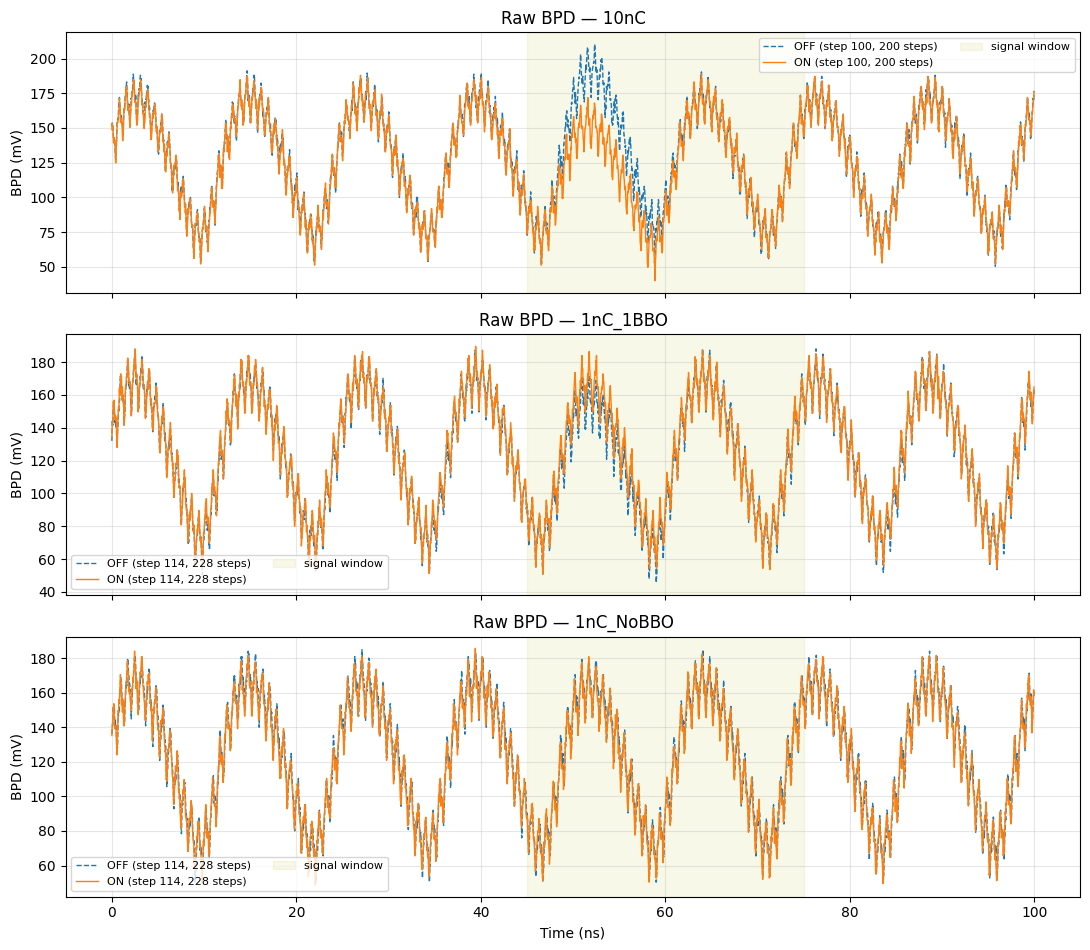

In [2]:
groups = {}
for s in SCANS:
    groups.setdefault(s['group'], []).append(s)

n_groups = len(groups)
fig, axes = plt.subplots(n_groups, 1, figsize=(11, 3.2*n_groups), sharex=True)
if n_groups == 1: axes = [axes]

for ax, (gname, gscans) in zip(axes, groups.items()):
    for s in gscans:
        d      = np.load(s['path'])
        t_ns   = 1e9 * d['x'][0, :]
        traces = d['BPDwf'].mean(axis=1)        # (steps, 5000) mean of 5 shots
        mid    = traces.shape[0] // 2
        ls = '-' if s['dipole'] == 'ON' else '--'
        ax.plot(t_ns, mV*traces[mid], ls=ls, lw=1.0,
                label=f"{s['dipole']} (step {mid}, {traces.shape[0]} steps)")
    ax.axvspan(SIGNAL_START_NS, SIGNAL_END_NS, color='C8', alpha=0.10, label='signal window')
    ax.set_ylabel('BPD (mV)')
    ax.set_title(f"Raw BPD — {gname}")
    ax.legend(fontsize=8, ncols=2); ax.grid(alpha=0.3)
axes[-1].set_xlabel('Time (ns)')
plt.tight_layout()
plt.savefig(f'{OUT}/raw_BPD_per_group.png', dpi=180, bbox_inches='tight')
plt.show()

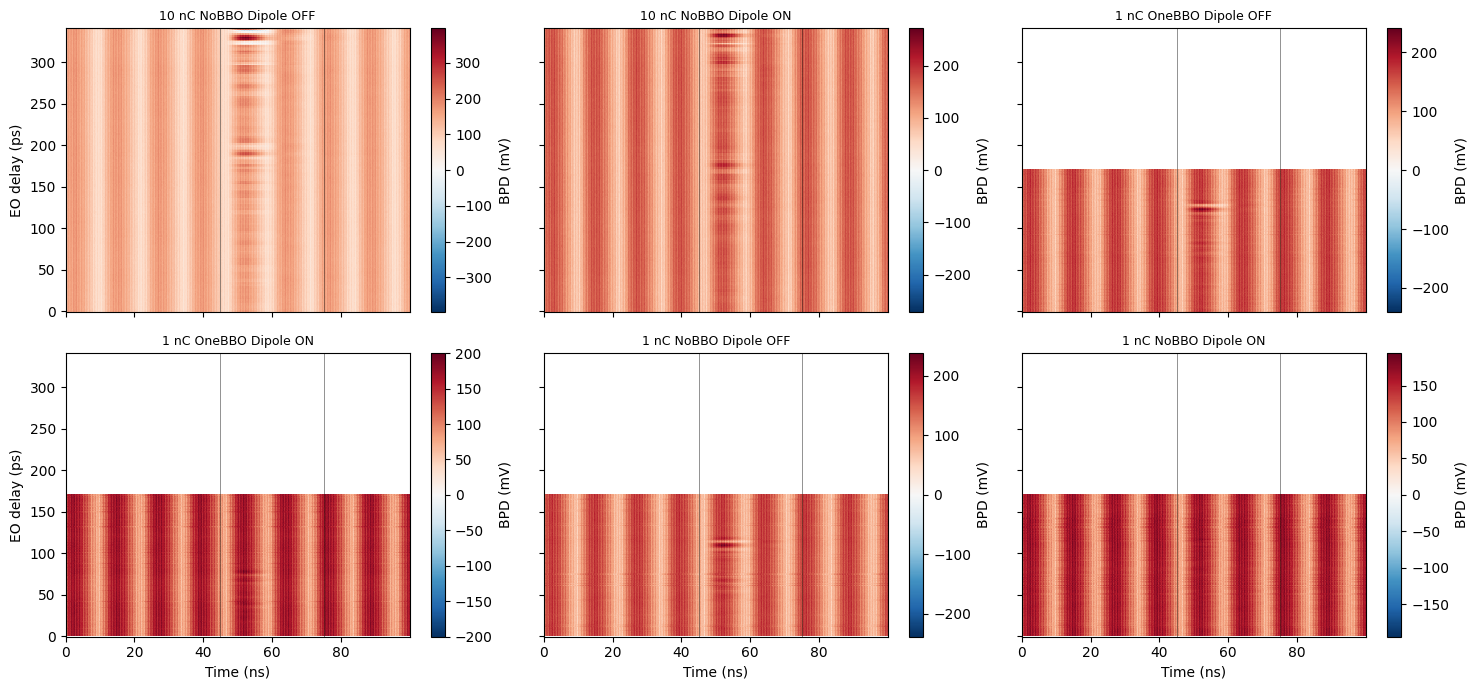

In [3]:
# Heatmap of every delay step's raw BPD trace — one panel per scan
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
axes = axes.ravel()
for ax, s in zip(axes, SCANS):
    d        = np.load(s['path'])
    t_ns     = 1e9 * d['x'][0, :]
    traces   = d['BPDwf'].mean(axis=1) * mV
    phase    = d['phase']
    delay_ps = (phase - phase[0]) / RF_Hz / 360 * 1e12
    pcm = ax.pcolormesh(t_ns, delay_ps, traces, cmap='RdBu_r',
                        vmin=-np.abs(traces).max(), vmax=np.abs(traces).max(),
                        shading='auto')
    ax.set_title(s['label'], fontsize=9)
    ax.axvline(SIGNAL_START_NS, color='k', lw=0.6, alpha=0.5)
    ax.axvline(SIGNAL_END_NS,   color='k', lw=0.6, alpha=0.5)
    plt.colorbar(pcm, ax=ax, label='BPD (mV)')
for ax in axes[3:]:
    ax.set_xlabel('Time (ns)')
for ax in (axes[0], axes[3]):
    ax.set_ylabel('EO delay (ps)')
plt.tight_layout()
plt.savefig(f'{OUT}/raw_BPD_heatmaps.png', dpi=180, bbox_inches='tight')
plt.show()

## Section 2: Spectral pipeline (identical to Charge_Spectral_Analysis)

Period-fill baseline → low-pass FFT → variance-peak window → averaged probe → signal-vs-delay.

In [4]:
def _period_fill(t_ns, s0, s1):
    dt   = (t_ns[-1]-t_ns[0])/(len(t_ns)-1)
    T    = T_LASER_NS/dt
    i0   = int(round(s0/dt)); i1 = int(round(s1/dt))
    idx  = np.arange(i0,i1)
    nl   = np.ceil((idx+1-i0)/T).astype(int); nr = np.ceil((i1-idx)/T).astype(int)
    return i0,i1, np.round(idx-nl*T).astype(int), np.round(idx+nr*T).astype(int)

def fft_lp(res, dt_ns):
    n=res.shape[1]; freqs=np.fft.rfftfreq(n,d=dt_ns)
    filt=np.exp(-0.5*(freqs/FFT_SIGMA_GHZ)**(2*FFT_ORDER))
    return np.fft.irfft(np.fft.rfft(res,axis=1)*filt,n=n,axis=1)

def extract(path):
    d=np.load(path); t_ns=1e9*d['x'][0,:]
    phase=d['phase']; delay_ps=(phase-phase[0])/RF_Hz/360*1e12
    dt=( t_ns[-1]-t_ns[0])/(len(t_ns)-1)
    traces=d['BPDwf'].mean(axis=1)
    i0,i1,sl,sr=_period_fill(t_ns,SIGNAL_START_NS,SIGNAL_END_NS)
    bl=traces.copy(); bl[:,i0:i1]=0.5*(traces[:,sl]+traces[:,sr])
    res=fft_lp(traces-bl,dt)
    tp=res.var(axis=0).argmax()
    win=slice(max(0,tp-PROBE_HALF_WIN),min(res.shape[1],tp+PROBE_HALF_WIN))
    sig=res[:,win].mean(axis=1)
    return delay_ps, sig

results=[]
for s in SCANS:
    dp, sig = extract(s['path'])
    results.append({**s, 'delay_ps':dp, 'sig':sig})
    print(f"{s['label']:<28}: peak={mV*np.abs(sig).max():6.2f} mV  steps={len(dp):3d}  span={dp[-1]-dp[0]:.1f} ps")

10 nC NoBBO Dipole OFF      : peak=244.16 mV  steps=200  span=340.2 ps
10 nC NoBBO Dipole ON       : peak= 87.11 mV  steps=200  span=340.2 ps
1 nC OneBBO Dipole OFF      : peak= 63.99 mV  steps=228  span=170.7 ps
1 nC OneBBO Dipole ON       : peak= 18.78 mV  steps=228  span=170.7 ps
1 nC NoBBO Dipole OFF       : peak= 61.35 mV  steps=228  span=170.7 ps
1 nC NoBBO Dipole ON        : peak=  7.85 mV  steps=228  span=170.7 ps


### Filtered residual heatmaps (flank-filter + super-Gaussian low-pass)

Same baseline-strip procedure as `FullAnalysis.ipynb`: inside the 45–75 ns signal window,
replace the trace with the average of the two adjacent laser periods (the *flanks*), subtract,
then apply the σ = 0.35 GHz, order-6 super-Gaussian low-pass on each delay row. The residual is
plotted as a (time × EO-delay) heatmap with symmetric color limits at the 98th percentile.

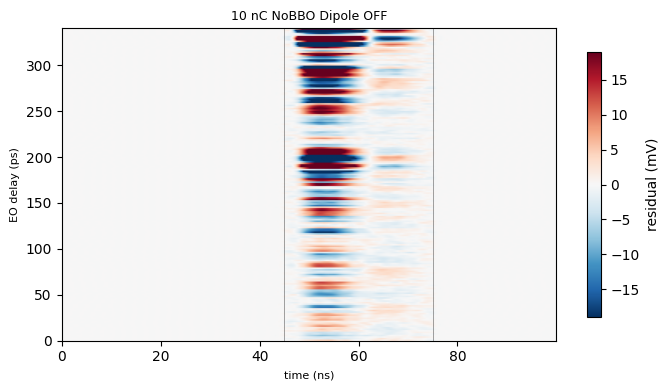

Saved Results/dipole_longscan/heatmaps/10_nc_nobbo_dipole_off_heatmap.png


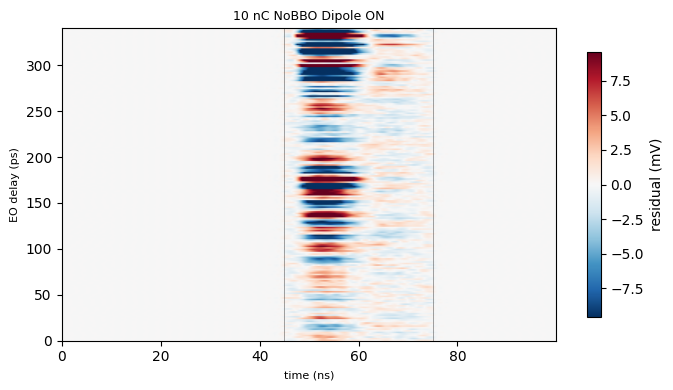

Saved Results/dipole_longscan/heatmaps/10_nc_nobbo_dipole_on_heatmap.png


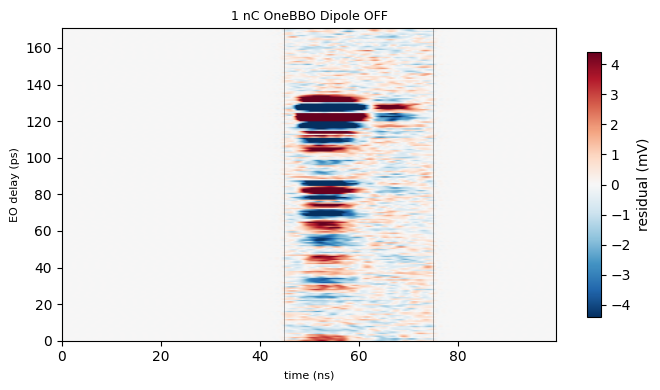

Saved Results/dipole_longscan/heatmaps/1_nc_onebbo_dipole_off_heatmap.png


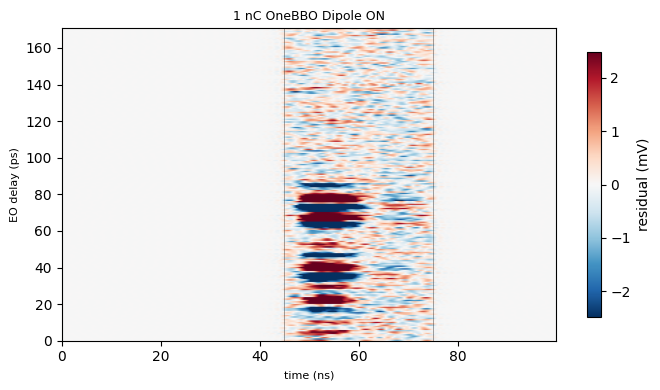

Saved Results/dipole_longscan/heatmaps/1_nc_onebbo_dipole_on_heatmap.png


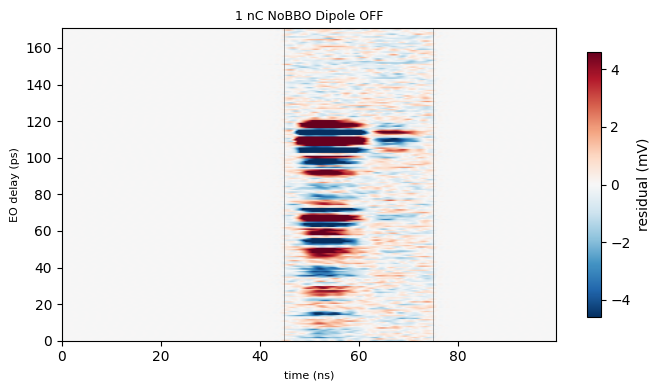

Saved Results/dipole_longscan/heatmaps/1_nc_nobbo_dipole_off_heatmap.png


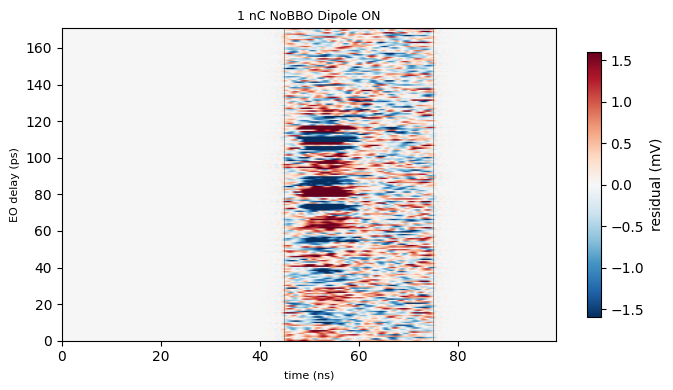

Saved Results/dipole_longscan/heatmaps/1_nc_nobbo_dipole_on_heatmap.png


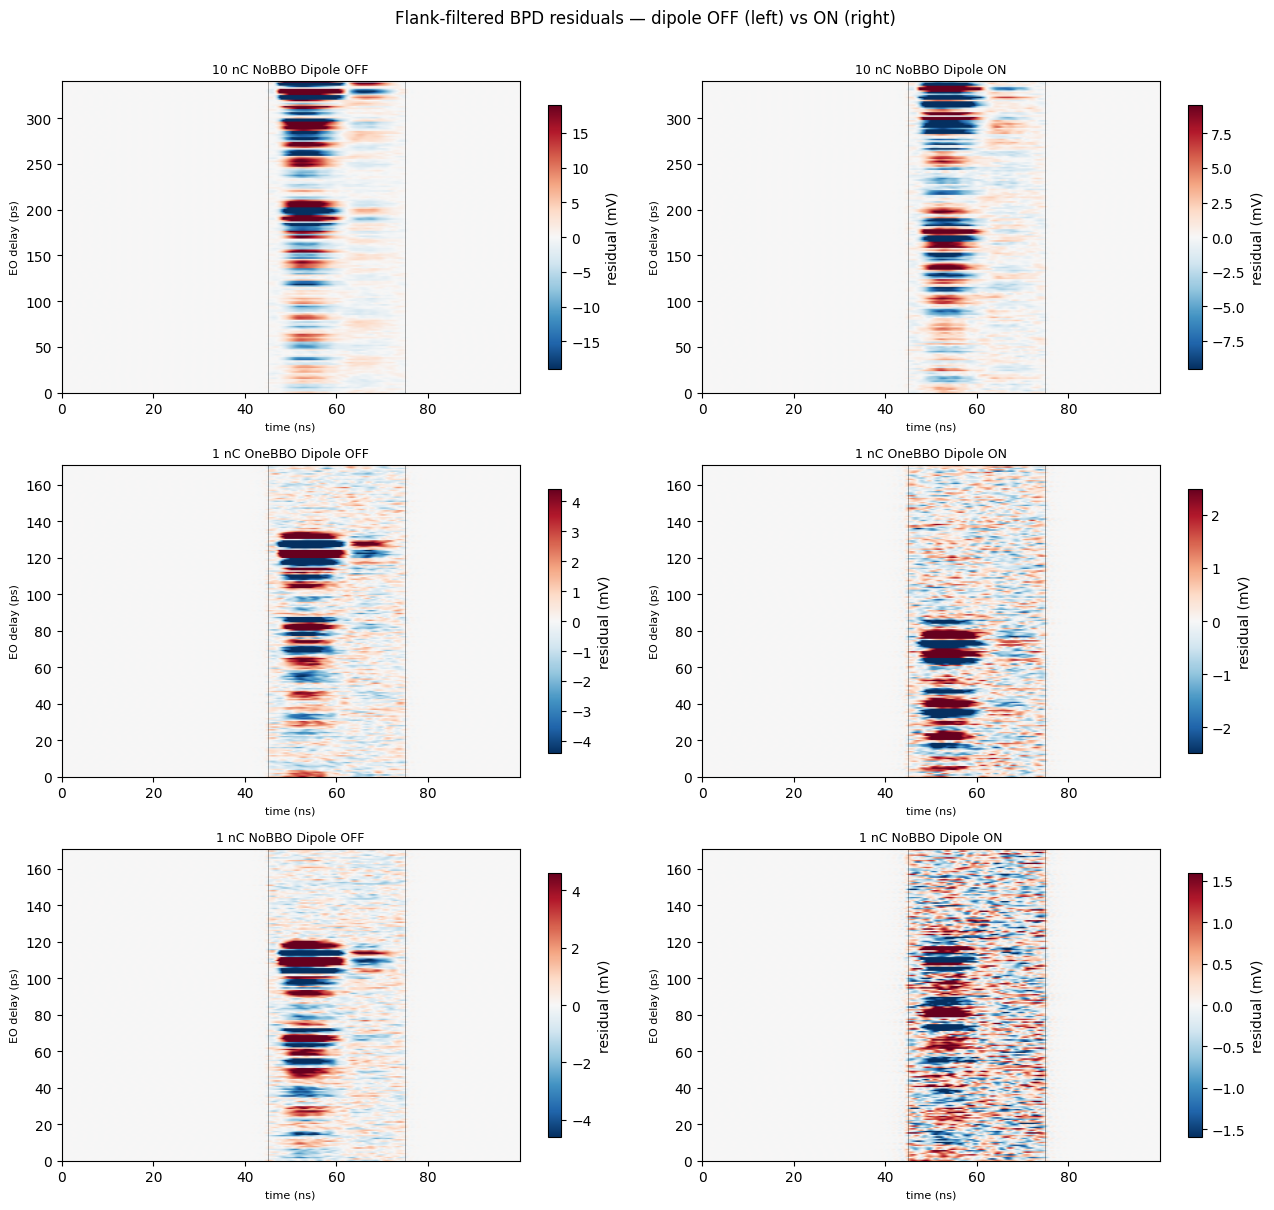

Saved Results/dipole_longscan/heatmaps/dipole_pair_heatmaps.png


In [5]:
# ── Filtered residual heatmaps (flank-filter + super-Gaussian LP) ───────────
HM_DIR = f'{OUT}/heatmaps'
os.makedirs(HM_DIR, exist_ok=True)

def compute_residual(path):
    d        = np.load(path)
    t_ns     = 1e9 * d['x'][0, :]
    phase    = d['phase']
    delay_ps = (phase - phase[0]) / RF_Hz / 360 * 1e12
    dt_ns    = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    traces   = d['BPDwf'].mean(axis=1)

    # Flank-filter baseline: replace signal window with avg of left/right laser periods
    i0, i1, sl, sr = _period_fill(t_ns, SIGNAL_START_NS, SIGNAL_END_NS)
    baseline = traces.copy()
    baseline[:, i0:i1] = 0.5 * (traces[:, sl] + traces[:, sr])

    # Super-Gaussian low-pass on the residual rows
    residual = fft_lp(traces - baseline, dt_ns)
    return {'t_ns': t_ns, 'delay_ps': delay_ps, 'residual': residual}

residuals = []
for s in SCANS:
    r = compute_residual(s['path'])
    r['label'] = s['label']
    residuals.append(r)

def draw_heatmap(ax, r, title=None):
    extent = [r['t_ns'][0], r['t_ns'][-1],
              r['delay_ps'][0], r['delay_ps'][-1]]
    vmax = np.percentile(np.abs(mV * r['residual']), 98)
    im = ax.imshow(mV * r['residual'], aspect='auto', extent=extent,
                   origin='lower', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(title or r['label'], fontsize=9)
    ax.set_xlabel('time (ns)', fontsize=8)
    ax.set_ylabel('EO delay (ps)', fontsize=8)
    ax.axvline(SIGNAL_START_NS, color='k', lw=0.5, alpha=0.5)
    ax.axvline(SIGNAL_END_NS,   color='k', lw=0.5, alpha=0.5)
    plt.colorbar(im, ax=ax, label='residual (mV)', shrink=0.85)

# Individual files per scan
def lab_to_file(lab):
    return (lab.lower()
            .replace(' ', '_')
            .replace('.', 'p')
            .replace('/', '_'))

for r in residuals:
    fig, ax = plt.subplots(figsize=(7, 4))
    draw_heatmap(ax, r)
    plt.tight_layout()
    fname = f'{HM_DIR}/{lab_to_file(r["label"])}_heatmap.png'
    plt.savefig(fname, dpi=180, bbox_inches='tight')
    plt.show()
    print(f'Saved {fname}')

# Combined 2x3 panel — ON/OFF pairs aligned by group
order = ['10 nC NoBBO Dipole OFF', '10 nC NoBBO Dipole ON',
         '1 nC OneBBO Dipole OFF', '1 nC OneBBO Dipole ON',
         '1 nC NoBBO Dipole OFF',  '1 nC NoBBO Dipole ON']
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, lab in zip(axes.ravel(), order):
    r = next(r for r in residuals if r['label'] == lab)
    draw_heatmap(ax, r)
plt.suptitle('Flank-filtered BPD residuals — dipole OFF (left) vs ON (right)', fontsize=12, y=1.005)
plt.tight_layout()
plt.savefig(f'{HM_DIR}/dipole_pair_heatmaps.png', dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved {HM_DIR}/dipole_pair_heatmaps.png')


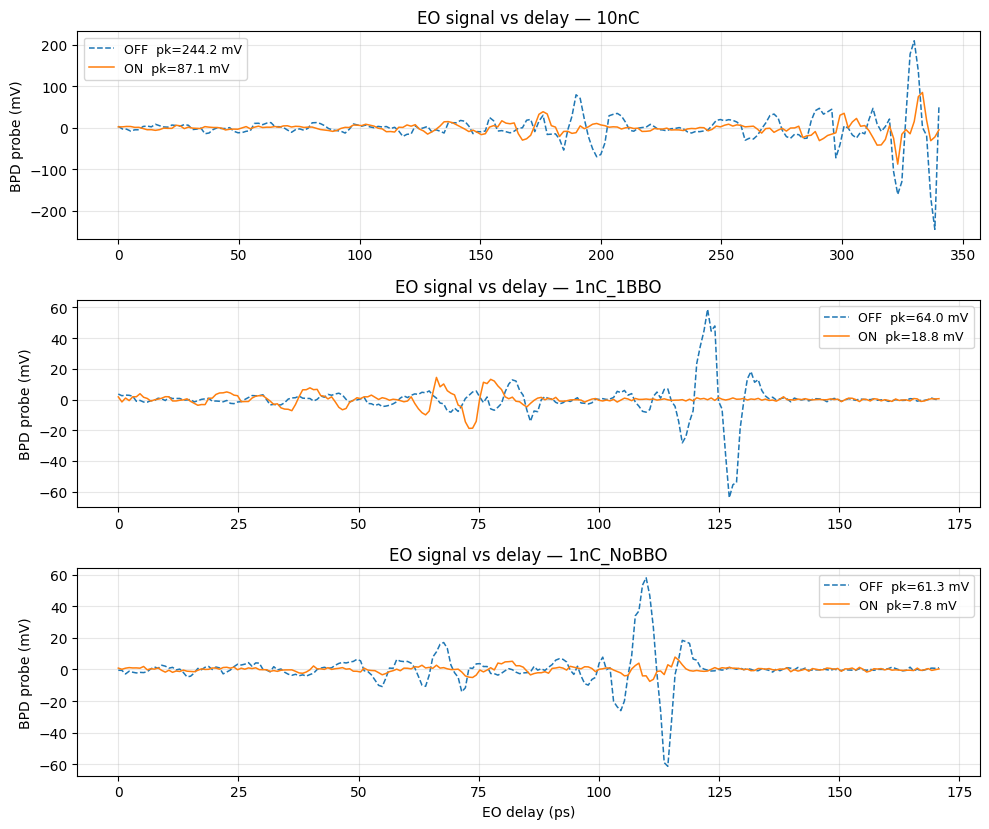

In [6]:
# Signal vs delay, per dipole-pair group — ON solid, OFF dashed
fig, axes = plt.subplots(n_groups, 1, figsize=(10, 2.8*n_groups), sharex=False)
if n_groups == 1: axes = [axes]
for ax, (gname, gscans) in zip(axes, groups.items()):
    for s in gscans:
        r = next(r for r in results if r['path'] == s['path'])
        ls = '-' if s['dipole'] == 'ON' else '--'
        ax.plot(r['delay_ps'], mV*r['sig'], ls=ls, lw=1.1,
                label=f"{s['dipole']}  pk={mV*np.abs(r['sig']).max():.1f} mV")
    ax.set_title(f'EO signal vs delay — {gname}')
    ax.set_ylabel('BPD probe (mV)')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
axes[-1].set_xlabel('EO delay (ps)')
plt.tight_layout()
plt.savefig(f'{OUT}/signal_vs_delay.png', dpi=180, bbox_inches='tight')
plt.show()

## Section 3: THz spectra (Hanning FFT of signal-vs-delay)

Same formula as `Charge_Spectral_Analysis.ipynb` cell 4.

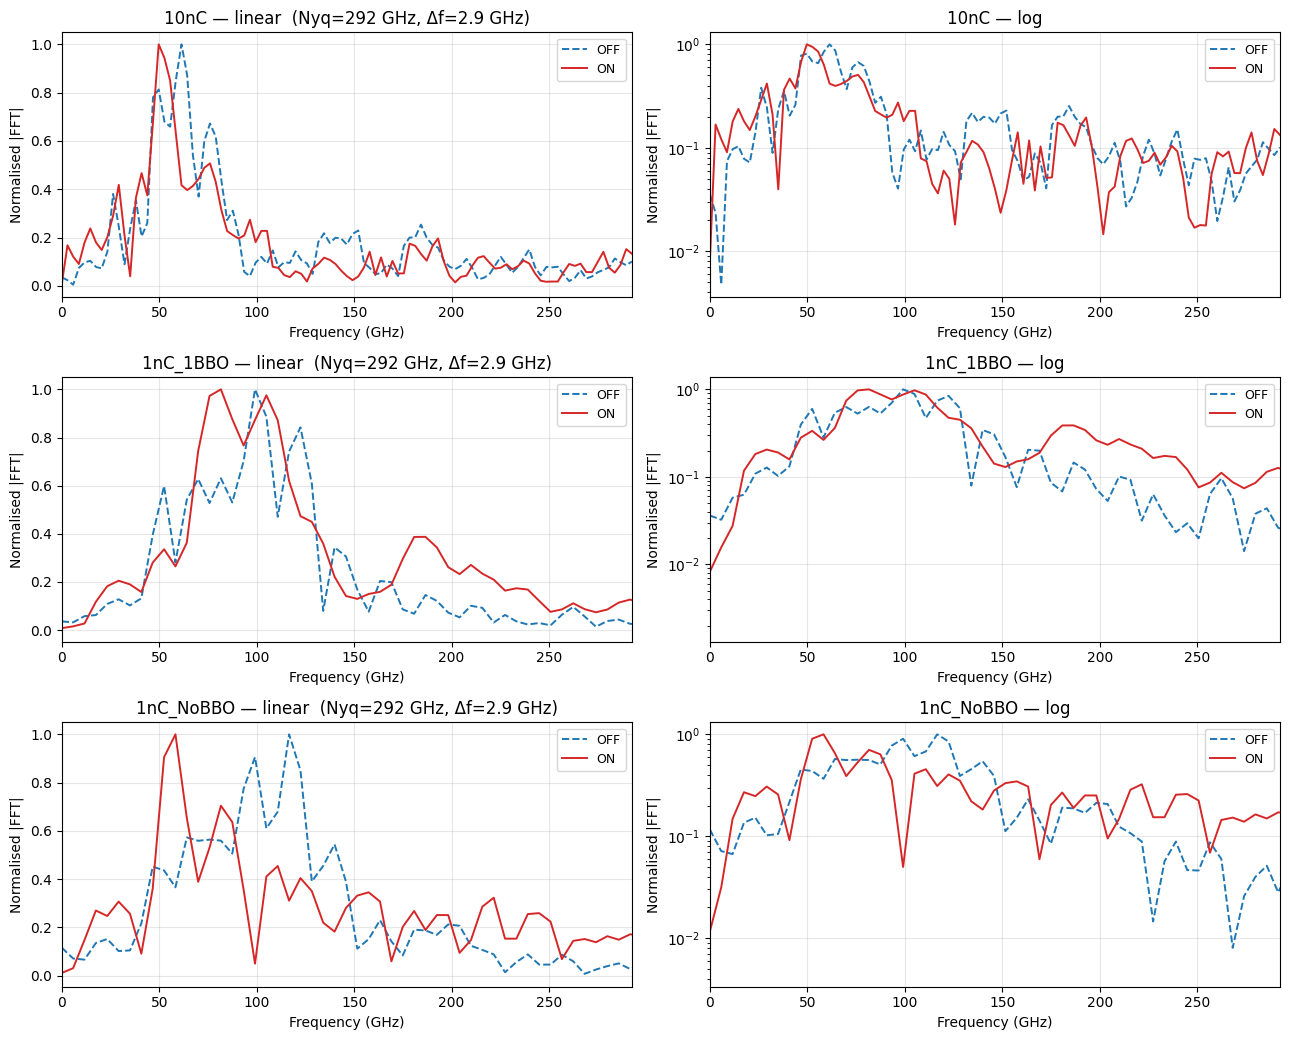

In [7]:
spectra = []
for r in results:
    dp, sig = r['delay_ps'], r['sig']
    n     = len(sig)
    dt_ps = (dp[-1]-dp[0])/(n-1)
    win   = np.hanning(n)
    F     = np.abs(np.fft.rfft(sig*win))
    freq  = np.fft.rfftfreq(n, d=dt_ps*1e-12)/1e9  # GHz
    spectra.append({**r, 'freq_GHz':freq, 'spec':F, 'dt_ps':dt_ps, 'n':n})

nyq = 0.5/(spectra[0]['dt_ps']*1e-3)
df  = 1/(spectra[0]['n']*spectra[0]['dt_ps']*1e-3)

colors = {'OFF': 'C0', 'ON': 'C3'}
fig, axes = plt.subplots(n_groups, 2, figsize=(13, 3.5*n_groups))
if n_groups == 1: axes = axes[None, :]
for row, (gname, gscans) in enumerate(groups.items()):
    ax1, ax2 = axes[row]
    for s in gscans:
        sp = next(sp for sp in spectra if sp['path'] == s['path'])
        nrm = sp['spec'].max() if sp['spec'].max() > 0 else 1.0
        ls = '-' if s['dipole'] == 'ON' else '--'
        ax1.plot(sp['freq_GHz'], sp['spec']/nrm, color=colors[s['dipole']], ls=ls, lw=1.4,
                 label=f"{s['dipole']}")
        ax2.semilogy(sp['freq_GHz'], sp['spec']/nrm, color=colors[s['dipole']], ls=ls, lw=1.4,
                     label=f"{s['dipole']}")
    for ax in (ax1, ax2):
        ax.set_xlim(0, min(600, nyq))
        ax.set_xlabel('Frequency (GHz)')
        ax.set_ylabel('Normalised |FFT|')
        ax.grid(alpha=0.3); ax.legend(fontsize=9)
    ax1.set_title(f'{gname} — linear  (Nyq={nyq:.0f} GHz, Δf={df:.1f} GHz)')
    ax2.set_title(f'{gname} — log')
plt.tight_layout()
plt.savefig(f'{OUT}/spectra_dipole_pairs.png', dpi=180, bbox_inches='tight')
plt.show()

scan                         group       dipole     Q    centroid      peak    BPD pk
10 nC NoBBO Dipole OFF       10nC        OFF    10.00     104.2 GHz   61.4 GHz 244.16 mV
10 nC NoBBO Dipole ON        10nC        ON     10.00      99.3 GHz   49.7 GHz  87.11 mV
1 nC OneBBO Dipole OFF       1nC_1BBO    OFF     1.00     190.1 GHz   99.1 GHz  63.99 mV
1 nC OneBBO Dipole ON        1nC_1BBO    ON      1.00     192.9 GHz   81.6 GHz  18.78 mV
1 nC NoBBO Dipole OFF        1nC_NoBBO   OFF     1.00     170.9 GHz  116.6 GHz  61.35 mV
1 nC NoBBO Dipole ON         1nC_NoBBO   ON      1.00     228.3 GHz   58.3 GHz   7.85 mV


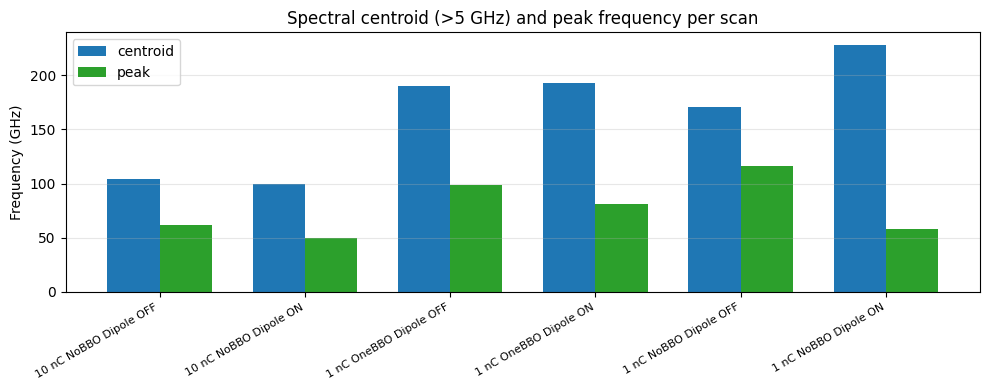

In [8]:
# Spectral centroid (>5 GHz) and peak frequency, per scan
rows = []
for sp in spectra:
    f, s = sp['freq_GHz'], sp['spec']
    m    = f > 5
    cen  = (f[m]*s[m]).sum() / s[m].sum()
    pk   = f[s.argmax()]
    pkmV = mV * np.abs(sp['sig']).max()
    rows.append((sp['label'], sp['group'], sp['dipole'], sp['Q'], cen, pk, pkmV))

print(f"{'scan':<28} {'group':<11} {'dipole':<6} {'Q':>5}  {'centroid':>10}  {'peak':>8}  {'BPD pk':>8}")
for lab, g, dp, Q, c, p, pkmV in rows:
    print(f"{lab:<28} {g:<11} {dp:<6} {Q:5.2f}  {c:8.1f} GHz {p:6.1f} GHz {pkmV:6.2f} mV")

# Bar comparison
labels = [r[0] for r in rows]
cens   = [r[4] for r in rows]
peaks  = [r[5] for r in rows]
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(rows))
ax.bar(x-0.18, cens, width=0.36, label='centroid', color='C0')
ax.bar(x+0.18, peaks, width=0.36, label='peak', color='C2')
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Frequency (GHz)')
ax.set_title('Spectral centroid (>5 GHz) and peak frequency per scan')
ax.grid(axis='y', alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(f'{OUT}/centroid_peak_bars.png', dpi=180, bbox_inches='tight')
plt.show()

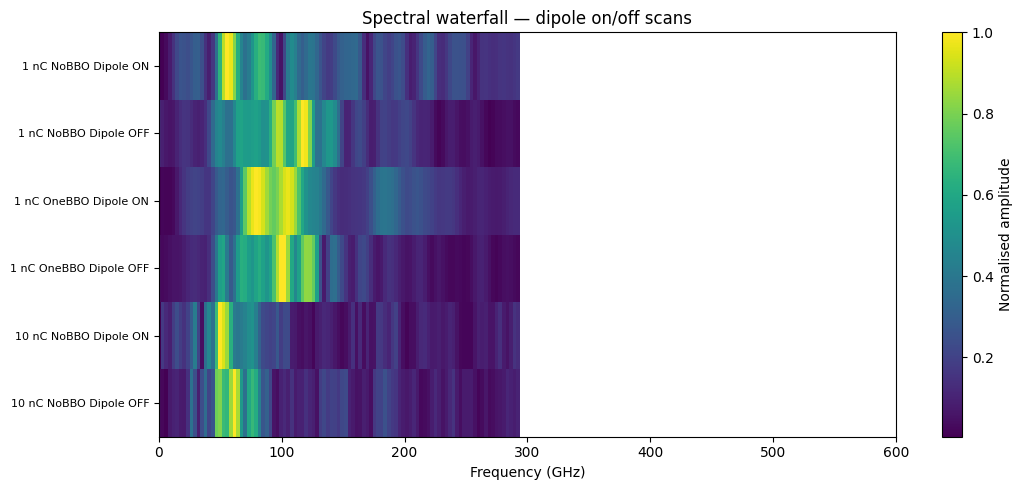

In [9]:
# Spectral waterfall — all scans on a common freq grid
freq_ref = spectra[0]['freq_GHz']
spec_mat = np.zeros((len(spectra), len(freq_ref)))
row_lab  = []
for i, sp in enumerate(spectra):
    cs = CubicSpline(sp['freq_GHz'], sp['spec'])
    s  = np.clip(cs(freq_ref), 0, None)
    s /= (s.max() if s.max() > 0 else 1.0)
    spec_mat[i] = s
    row_lab.append(sp['label'])

fig, ax = plt.subplots(figsize=(11, 5))
pcm = ax.pcolormesh(freq_ref, np.arange(len(spectra)), spec_mat, cmap='viridis', shading='auto')
ax.set_yticks(np.arange(len(spectra))); ax.set_yticklabels(row_lab, fontsize=8)
ax.set_xlabel('Frequency (GHz)'); ax.set_xlim(0, 600)
ax.set_title('Spectral waterfall — dipole on/off scans')
plt.colorbar(pcm, ax=ax, label='Normalised amplitude')
plt.tight_layout()
plt.savefig(f'{OUT}/spectral_waterfall.png', dpi=180, bbox_inches='tight')
plt.show()

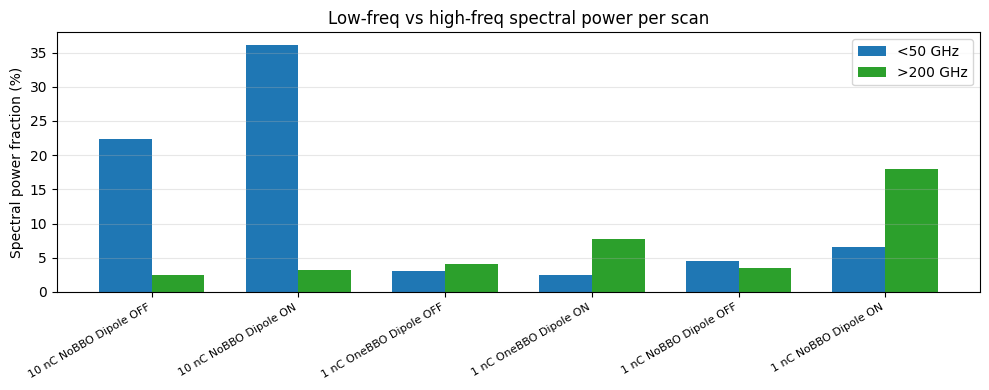

  10 nC NoBBO Dipole OFF        <50 GHz =  22.4%   >200 GHz =   2.4%
  10 nC NoBBO Dipole ON         <50 GHz =  36.1%   >200 GHz =   3.2%
  1 nC OneBBO Dipole OFF        <50 GHz =   3.1%   >200 GHz =   4.1%
  1 nC OneBBO Dipole ON         <50 GHz =   2.5%   >200 GHz =   7.7%
  1 nC NoBBO Dipole OFF         <50 GHz =   4.5%   >200 GHz =   3.5%
  1 nC NoBBO Dipole ON          <50 GHz =   6.6%   >200 GHz =  18.0%


In [10]:
# Spectral power fractions (low <50 GHz, high >200 GHz) — matches Charge_Spectral_Analysis cell 10
lf, hf = [], []
for sp in spectra:
    f, p = sp['freq_GHz'], sp['spec']**2
    tot  = p.sum() if p.sum() > 0 else 1.0
    lf.append(p[f < 50].sum() / tot)
    hf.append(p[f > 200].sum() / tot)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(spectra))
ax.bar(x-0.18, [100*v for v in lf], width=0.36, label='<50 GHz',  color='C0')
ax.bar(x+0.18, [100*v for v in hf], width=0.36, label='>200 GHz', color='C2')
ax.set_xticks(x); ax.set_xticklabels([sp['label'] for sp in spectra], rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Spectral power fraction (%)')
ax.set_title('Low-freq vs high-freq spectral power per scan')
ax.grid(axis='y', alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(f'{OUT}/power_fractions.png', dpi=180, bbox_inches='tight')
plt.show()

for sp, l, h in zip(spectra, lf, hf):
    print(f"  {sp['label']:<28}  <50 GHz = {100*l:5.1f}%   >200 GHz = {100*h:5.1f}%")

## Section 4: Long-period wakefield scan — `longscan_dipoleON_10nC`

This run is stored as **per-period extrema only** (peak/valley amplitudes and sample positions),
not full BPD waveforms. The phase axis spans 350° → 688.7° (~339°, ≈ 11.6 ns of EO delay at
81.25 MHz) — ~30× longer than the fine scans. We can still run the same spectral pipeline by
treating the **per-shot wake amplitude** (mean peak − mean valley over all captured periods)
as the signal vs delay.

Each phase appears as ~4 repeat shots in the file; we average within each unique phase.

In [11]:
ls_raw = np.load(LONGSCAN_PATH, allow_pickle=True).item()
phase  = np.asarray(ls_raw['phase'], dtype=float)
peaks  = ls_raw['peak']            # list of lists, variable length per shot
valys  = ls_raw['valley']
peakps = ls_raw['peak_pos']

# Per-shot wake amplitude = mean(peak) - mean(valley) over the periods captured this shot
amp_shot      = np.array([np.mean(p) - np.mean(v) for p, v in zip(peaks, valys)])
first_peak    = np.array([p[0] for p in peaks])
first_valley  = np.array([v[0] for v in valys])
first_amp     = first_peak - first_valley
n_per_shot    = np.array([len(p) for p in peaks])

# Collapse repeat shots at the same phase
uniq_phase, inv = np.unique(phase, return_inverse=True)
def collapse(x):
    out = np.zeros_like(uniq_phase, dtype=float)
    cnt = np.zeros_like(uniq_phase, dtype=float)
    np.add.at(out, inv, x); np.add.at(cnt, inv, 1.0)
    return out / np.maximum(cnt, 1)
amp_mean   = collapse(amp_shot)
amp1_mean  = collapse(first_amp)

delay_ps_ls = (uniq_phase - uniq_phase[0]) / RF_Hz / 360 * 1e12
print(f"Long scan: {len(phase)} shots over {len(uniq_phase)} unique phases")
print(f"  phase span: {phase.min():.2f}° → {phase.max():.2f}°  ({phase.max()-phase.min():.2f}°)")
print(f"  delay span: {delay_ps_ls.max():.1f} ps  ({delay_ps_ls.max()/1000:.2f} ns)")
print(f"  periods/shot histogram: {dict(zip(*np.unique(n_per_shot, return_counts=True)))}")
print(f"  amp_shot range: {amp_shot.min():.3f} → {amp_shot.max():.3f}")

Long scan: 13611 shots over 3388 unique phases
  phase span: 350.00° → 688.70°  (338.70°)
  delay span: 11579.5 ps  (11.58 ns)
  periods/shot histogram: {np.int64(7): np.int64(7), np.int64(8): np.int64(9092), np.int64(9): np.int64(4512)}
  amp_shot range: 0.095 → 0.107


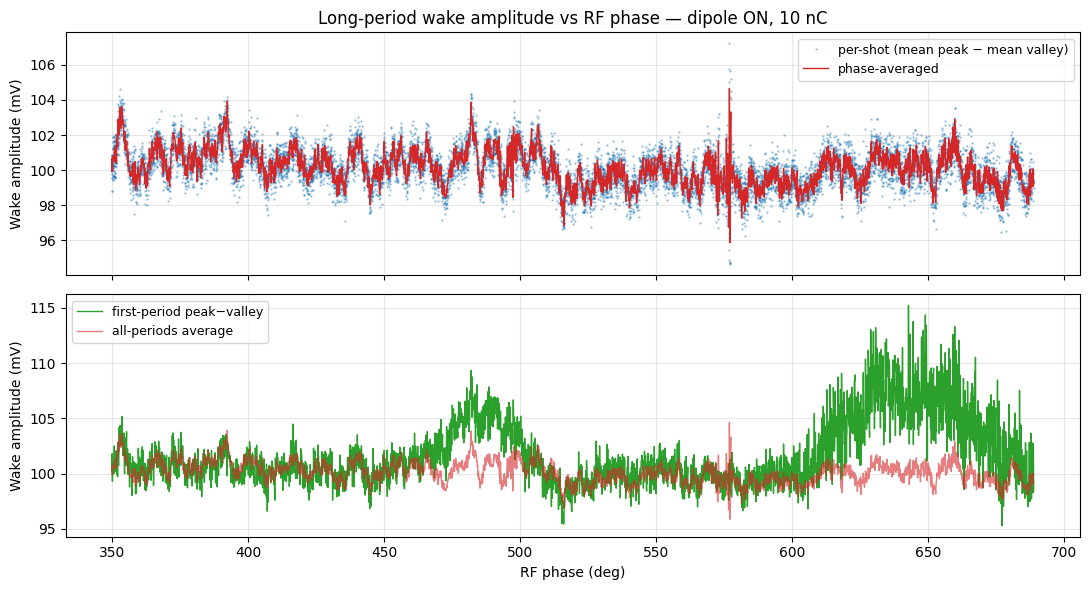

In [12]:
# Raw long-scan envelope: shot-by-shot and phase-averaged
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

ax = axes[0]
ax.plot(phase, mV*amp_shot, '.', ms=1.5, alpha=0.35, color='C0', label='per-shot (mean peak − mean valley)')
ax.plot(uniq_phase, mV*amp_mean, '-', lw=1.0, color='C3', label='phase-averaged')
ax.set_ylabel('Wake amplitude (mV)')
ax.set_title('Long-period wake amplitude vs RF phase — dipole ON, 10 nC')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(uniq_phase, mV*amp1_mean, '-', lw=1.0, color='C2', label='first-period peak−valley')
ax.plot(uniq_phase, mV*amp_mean,  '-', lw=1.0, color='C3', alpha=0.6, label='all-periods average')
ax.set_xlabel('RF phase (deg)'); ax.set_ylabel('Wake amplitude (mV)')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUT}/longscan_raw.png', dpi=180, bbox_inches='tight')
plt.show()

Long scan FFT: N=3388, dt=3.42 ps  →  Δf=0.086 GHz, Nyquist=146.2 GHz
Short scan (10 nC, dipole ON):    dt=1.71 ps  →  Δf=2.92 GHz


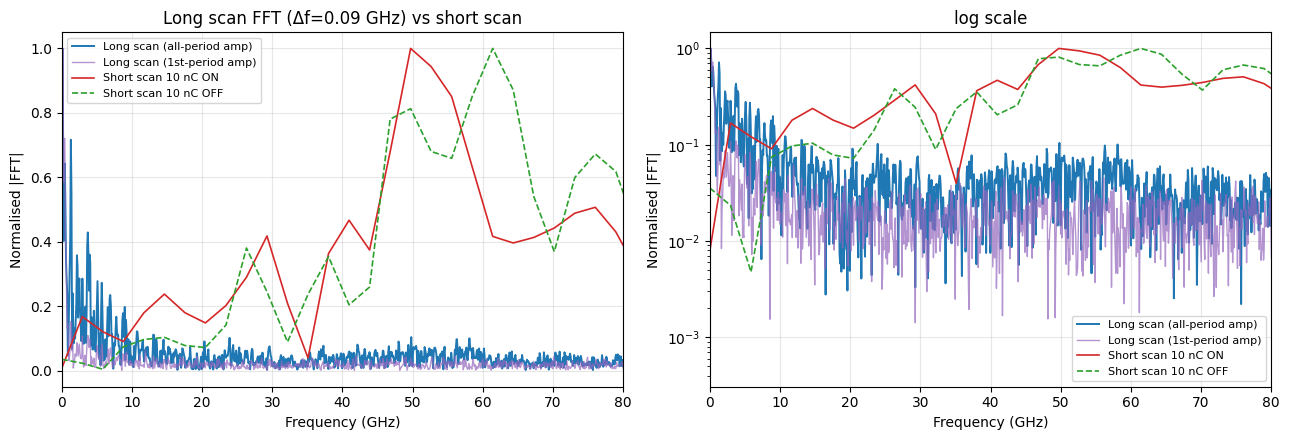

In [13]:
# Long-scan FFT — same Hanning-window pipeline as Section 3
def hann_fft(sig, dp):
    n     = len(sig)
    dt_ps = (dp[-1] - dp[0]) / (n - 1)
    win   = np.hanning(n)
    F     = np.abs(np.fft.rfft((sig - sig.mean()) * win))
    f     = np.fft.rfftfreq(n, d=dt_ps*1e-12) / 1e9
    return f, F, dt_ps

f_ls, F_ls, dt_ls = hann_fft(amp_mean,  delay_ps_ls)
f_l1, F_l1, _     = hann_fft(amp1_mean, delay_ps_ls)

# Comparison: 10 nC dipole ON short scan (same charge, dipole condition)
sp_short_on  = next(sp for sp in spectra if sp['path'].endswith('cosrsescaneQ10nC_wh4_0_dipoleON.npz'))
sp_short_off = next(sp for sp in spectra if sp['path'].endswith('cosrsescaneQ10nC_wh4_0_dipoleOFF.npz'))

df_ls = 1.0 / (len(amp_mean) * dt_ls * 1e-3)
nyq_ls = 0.5 / (dt_ls * 1e-3)
print(f"Long scan FFT: N={len(amp_mean)}, dt={dt_ls:.2f} ps  →  Δf={df_ls:.3f} GHz, Nyquist={nyq_ls:.1f} GHz")
print(f"Short scan (10 nC, dipole ON):    dt={sp_short_on['dt_ps']:.2f} ps  →  Δf={1/(sp_short_on['n']*sp_short_on['dt_ps']*1e-3):.2f} GHz")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, ylog in zip(axes, [False, True]):
    plot = ax.semilogy if ylog else ax.plot
    plot(f_ls, F_ls/F_ls.max(), color='C0', lw=1.4, label='Long scan (all-period amp)')
    plot(f_l1, F_l1/F_l1.max(), color='C4', lw=1.0, alpha=0.7, label='Long scan (1st-period amp)')
    plot(sp_short_on['freq_GHz'],  sp_short_on['spec']/sp_short_on['spec'].max(),  color='C3', ls='-',  lw=1.2, label='Short scan 10 nC ON')
    plot(sp_short_off['freq_GHz'], sp_short_off['spec']/sp_short_off['spec'].max(), color='C2', ls='--', lw=1.2, label='Short scan 10 nC OFF')
    ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('Normalised |FFT|')
    ax.set_xlim(0, 80); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_title(f'Long scan FFT (Δf={df_ls:.2f} GHz) vs short scan')
axes[1].set_title('log scale')
plt.tight_layout()
plt.savefig(f'{OUT}/longscan_fft.png', dpi=180, bbox_inches='tight')
plt.show()

In [14]:
# Long-scan summary stats
for tag, f, F in [('all-period amp', f_ls, F_ls), ('1st-period amp', f_l1, F_l1)]:
    m   = f > 0.1   # skip DC bin
    pk  = f[m][F[m].argmax()]
    cen = (f[m]*F[m]).sum() / F[m].sum()
    print(f"Long scan ({tag}):  peak={pk:6.2f} GHz   centroid={cen:6.2f} GHz")
for tag, sp in [('Short 10 nC ON', sp_short_on), ('Short 10 nC OFF', sp_short_off)]:
    f, S = sp['freq_GHz'], sp['spec']
    m   = f > 5
    pk  = f[S.argmax()]
    cen = (f[m]*S[m]).sum() / S[m].sum()
    print(f"{tag:<18}:  peak={pk:6.2f} GHz   centroid={cen:6.2f} GHz")

Long scan (all-period amp):  peak=  0.17 GHz   centroid= 47.22 GHz
Long scan (1st-period amp):  peak=  0.17 GHz   centroid= 60.08 GHz
Short 10 nC ON    :  peak= 49.72 GHz   centroid= 99.34 GHz
Short 10 nC OFF   :  peak= 61.42 GHz   centroid=104.16 GHz


### Long-scan heatmaps (flank-filter analog)

The longscan file holds only per-period **extrema** (peak/valley values and their BPD sample
positions), so the flank-filter cannot be re-run — there is no raw waveform to baseline-strip.
What we can do is reconstruct the filter's *output* directly: place each shot's peak amplitudes
(+) and valley amplitudes (−) at their recorded sample positions on a (time × EO-delay) grid
and average across the ~4 repeat shots per phase. This gives the same dipole/ON, baseline-stripped
(time × delay) view used for the short scans, just sparsely populated at the wake extrema.

A second heatmap recasts the same data on a (period-index × delay) axis — the natural way to
see wake-amplitude evolution across the captured oscillation periods.

Borrowed scope time axis: 5000 samples, dt=20.00 ps, span=0.0-100.0 ns


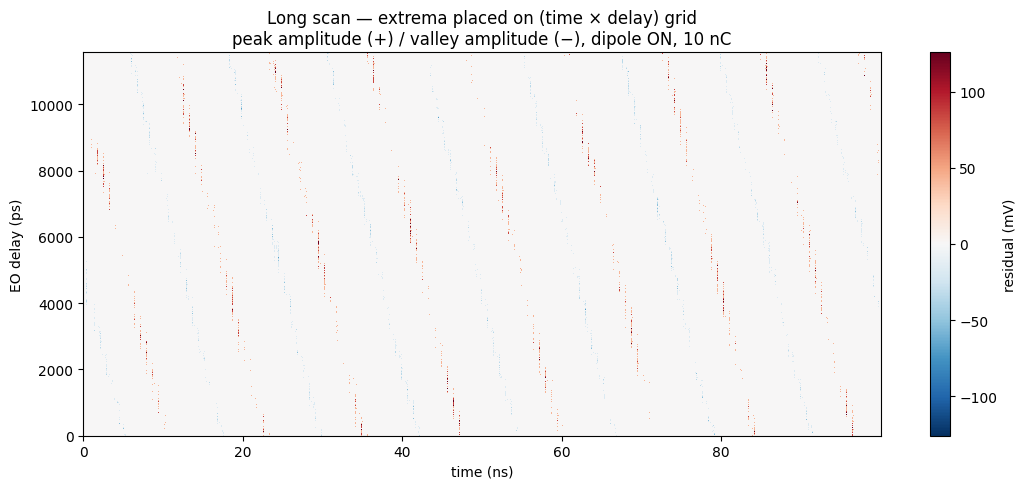

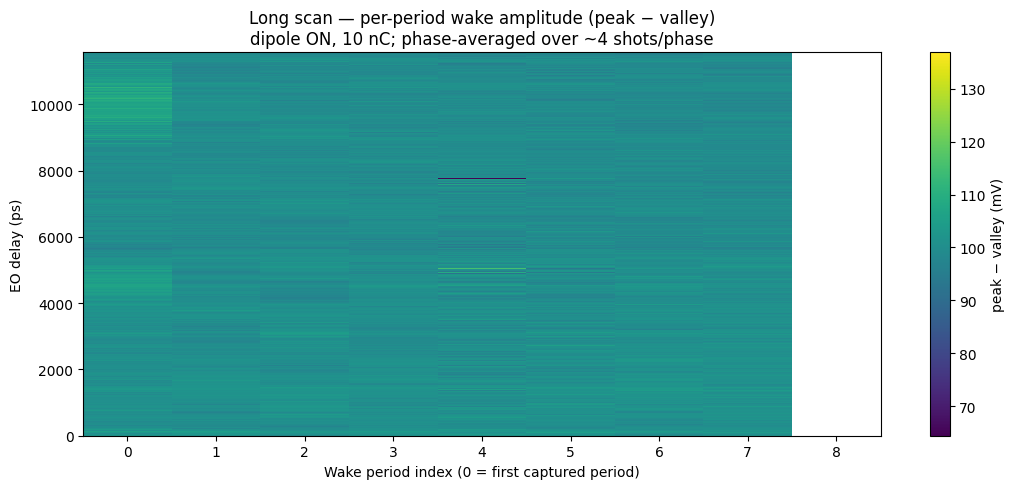

Saved Results/dipole_longscan/heatmaps/longscan_time_delay_heatmap.png
Saved Results/dipole_longscan/heatmaps/longscan_period_delay_heatmap.png
Per-period amplitude range: 64.40 → 136.91 mV


In [15]:
# ── Long-scan filtered-equivalent heatmaps ─────────────────────────────────
# Time axis: borrow the scope dt from the matched 10 nC dipoleON short scan
d_ref  = np.load('Data_raw/July31_/cosrsescaneQ10nC_wh4_0_dipoleON.npz')
t_ref  = 1e9 * d_ref['x'][0, :]                 # ns
dt_ns  = (t_ref[-1] - t_ref[0]) / (len(t_ref) - 1)
n_samp = len(t_ref)
print(f'Borrowed scope time axis: {n_samp} samples, dt={dt_ns*1e3:.2f} ps, span={t_ref[0]:.1f}-{t_ref[-1]:.1f} ns')

# Accumulate signed extrema on (unique_phase × n_samp) grid
n_phase = len(uniq_phase)
grid    = np.zeros((n_phase, n_samp), dtype=float)
counts  = np.zeros(n_phase, dtype=float)
for shot_i, ph_i in enumerate(inv):
    counts[ph_i] += 1
    for p, pos in zip(peaks[shot_i],  peakps[shot_i]):
        if 0 <= pos < n_samp: grid[ph_i, pos] += p
    for v, pos in zip(valys[shot_i], ls_raw['valley_pos'][shot_i]):
        if 0 <= pos < n_samp: grid[ph_i, pos] -= v
grid /= np.maximum(counts[:, None], 1)

# Plot 1: (time × EO-delay) sparse heatmap — mimics the short-scan filtered residual layout
vmax = np.percentile(np.abs(grid[grid != 0]), 98) * mV
fig, ax = plt.subplots(figsize=(11, 5))
extent = [t_ref[0], t_ref[-1], delay_ps_ls[0], delay_ps_ls[-1]]
im = ax.imshow(mV*grid, aspect='auto', extent=extent, origin='lower',
               cmap='RdBu_r', vmin=-vmax, vmax=vmax, interpolation='nearest')
ax.set_xlabel('time (ns)'); ax.set_ylabel('EO delay (ps)')
ax.set_title('Long scan — extrema placed on (time × delay) grid\n'
             'peak amplitude (+) / valley amplitude (−), dipole ON, 10 nC')
plt.colorbar(im, ax=ax, label='residual (mV)')
# Zoom x-axis onto the region that actually contains data
nonzero_cols = np.where(np.any(grid != 0, axis=0))[0]
if len(nonzero_cols):
    pad = 100
    ax.set_xlim(t_ref[max(0, nonzero_cols.min()-pad)],
                t_ref[min(n_samp-1, nonzero_cols.max()+pad)])
plt.tight_layout()
plt.savefig(f'{OUT}/heatmaps/longscan_time_delay_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

# Plot 2: (period-index × delay) heatmap of per-period peak-valley amplitude
max_periods = max(len(p) for p in peaks)
amp_pp = np.full((n_phase, max_periods), np.nan)
for shot_i, ph_i in enumerate(inv):
    n_pk = min(len(peaks[shot_i]), len(valys[shot_i]))
    for k in range(n_pk):
        a = peaks[shot_i][k] - valys[shot_i][k]
        if np.isnan(amp_pp[ph_i, k]):
            amp_pp[ph_i, k] = a
        else:
            amp_pp[ph_i, k] += a
# Convert sum→mean (counts per (phase, period) cell)
cell_counts = np.zeros_like(amp_pp)
for shot_i, ph_i in enumerate(inv):
    n_pk = min(len(peaks[shot_i]), len(valys[shot_i]))
    cell_counts[ph_i, :n_pk] += 1
amp_pp = np.where(cell_counts > 0, amp_pp/np.maximum(cell_counts,1), np.nan)

fig, ax = plt.subplots(figsize=(11, 5))
pcm = ax.pcolormesh(np.arange(max_periods), delay_ps_ls,
                    mV*amp_pp, cmap='viridis', shading='nearest')
ax.set_xlabel('Wake period index (0 = first captured period)')
ax.set_ylabel('EO delay (ps)')
ax.set_title('Long scan — per-period wake amplitude (peak − valley)\n'
             'dipole ON, 10 nC; phase-averaged over ~4 shots/phase')
plt.colorbar(pcm, ax=ax, label='peak − valley (mV)')
plt.tight_layout()
plt.savefig(f'{OUT}/heatmaps/longscan_period_delay_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

print(f'Saved {OUT}/heatmaps/longscan_time_delay_heatmap.png')
print(f'Saved {OUT}/heatmaps/longscan_period_delay_heatmap.png')
print(f'Per-period amplitude range: {mV*np.nanmin(amp_pp):.2f} → {mV*np.nanmax(amp_pp):.2f} mV')


## Notes / caveats

* **Long-scan signal model.** The longscan file has no raw BPD waveforms — only the
  peak/valley extrema arrays. The pipeline here treats `mean(peak) − mean(valley)` per shot
  as the wake amplitude, then averages across the ~4 repeat shots per RF phase. This is
  not identical to the short-scan `extract()` (which probes a fixed time bin in the BPD
  waveform), so absolute amplitude comparisons should be interpreted with care; relative
  spectral content is what matters.
* **Frequency resolution.** The long scan resolves ~30× lower in Δf than the short scans
  because of its much larger delay span — useful for the very low-frequency wake content.
  Its Nyquist is also lower (coarser delay step).
* **No dipole-OFF counterpart for the long scan.** Only the dipole-ON 10 nC long run
  exists in `Data_raw/`; the closest baseline is the short `cosrsescaneQ10nC_wh4_0_dipoleOFF.npz`
  scan over the overlapping phase window.
* **dB convention.** −3 dB ≡ ½ amplitude (group convention) — relevant if you extend
  this notebook with rising-edge cutoff fits like Section 3b of `Charge_Spectral_Analysis`.